# Bank Capital Credit Cycle

## Alcance y pregunta

¿El stress de pérdidas obliga a reducir crédito cuando suben ponderaciones de riesgo?

**Laboratorio estructural sintético.** La ampliación semanal sustituye el baseline OLS genérico por un experimento del mecanismo anunciado. No contiene estimaciones de datos de Colombia ni evidencia de desempeño productivo.

## Modelo y mecanismo

$$L_{max}=K/(k_{min}\,w)$$

Banco con capital 12 y cartera 100. Un stress destruye capital y aumenta el peso de riesgo. Se compara capacidad máxima con peso fijo y variable, usando mínimo de capital de 10% como parámetro hipotético, no una exigencia regulatoria.

### Supuestos de identificación

Balance agregado de un período; sin emisión de capital, beneficios, provisiones previas ni buffers regulatorios.

La verdad del DGP es conocida por construcción. Recuperar esa verdad comprueba implementación y diseño; no establece que el mecanismo describa una población observada.

## Configuración reproducible

Se usan NumPy, SciPy, Pandas y Matplotlib del entorno de investigación del repositorio. La semilla es fija, todos los cálculos se ejecutan desde los inputs y ninguna celda lee resultados precomputados. OLS incluye intercepto salvo fórmulas que lo excluyen explícitamente.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
COLORS=['#245C83','#B56A20','#637843']
SEED=20261018
REPLICATIONS=40

def ols_fit(y, regressors):
    """Intercept included; QR/SVD-backed least squares, no matrix inversion."""
    X=np.column_stack([np.ones(len(y)),regressors])
    coefficients,_,rank,_=np.linalg.lstsq(X,y,rcond=None)
    if rank<X.shape[1]: raise ValueError('Diseño sin rango completo')
    return coefficients,y-X@coefficients

def ar_process(rng,n,rho):
    if abs(rho)>=1: raise ValueError('Se requiere AR estacionario')
    draws=rng.normal(size=n+200); x=np.zeros(n+200)
    for t in range(1,len(x)): x[t]=rho*x[t-1]+draws[t]
    return x[200:]


## Datos y experimento

Banco con capital 12 y cartera 100. Un stress destruye capital y aumenta el peso de riesgo. Se compara capacidad máxima con peso fijo y variable, usando mínimo de capital de 10% como parámetro hipotético, no una exigencia regulatoria.

El siguiente código define el DGP o problema de equilibrio y sus comparadores. Las restricciones, oráculos analíticos y condiciones de factibilidad que corresponden al mecanismo se comprueban dentro de la función. Las cantidades monetarias se expresan en unidades sintéticas.

In [2]:
def experiment(rng,level,n=500):
    capital=12.;loans=100.;minimum=.10;base_weight=.8
    remaining=capital-level*loans;stress_weight=base_weight+2*level
    fixed=max(remaining/(minimum*base_weight),0);variable=max(remaining/(minimum*stress_weight),0)
    assert variable<=fixed+1e-12
    return {'Capacidad con peso fijo':fixed,'Capacidad con peso variable':variable,'Cartera inicial':loans},(np.array([0,1]),np.array([capital,remaining]))


### Un escenario reproducible

Cada métrica conserva su denominador y unidad conceptual; no se mezclan conteos, probabilidades y costos en un mismo eje. La tabla muestra el caso central de la malla, antes de resumir réplicas.

In [3]:
GRID=[0, 0.01, 0.03, 0.05, 0.08]
METRICS=['Capacidad con peso fijo', 'Capacidad con peso variable', 'Cartera inicial']
central=GRID[len(GRID)//2]
example,diagnostic=experiment(np.random.default_rng(SEED),central)
display(pd.DataFrame({'Métrica':list(example),'Valor':list(example.values())}))
print('Escenario central:',central,'; semilla:',SEED)


Escenario central: 0.03 ; semilla: 20261018


,Métrica,Valor
0,Capacidad con peso fijo,112.500000
1,Capacidad con peso variable,104.651163
2,Cartera inicial,100.000000


## Sensibilidad y variación entre réplicas

**Eje:** Pérdida como fracción de cartera.

Se conservan 40 réplicas por escenario. Se reinicia la misma secuencia de semillas para cada nivel: las comparaciones entre niveles comparten innovaciones cuando la dimensión del DGP lo permite. En mecanismos deterministas los cuantiles coinciden; esto no representa una incertidumbre estimada de parámetros. No se descartan resultados desfavorables.

In [4]:
records=[]
for level in GRID:
    for replicate in range(REPLICATIONS):
        metrics,_=experiment(np.random.default_rng(SEED+replicate),level)
        if set(metrics)!=set(METRICS): raise AssertionError('Métricas inconsistentes')
        for name,value in metrics.items():
            if not np.isfinite(value):raise ArithmeticError(f'Resultado no finito: {name}')
            records.append({'nivel':level,'replica':replicate,'metrica':name,'valor':float(value)})
raw=pd.DataFrame(records)
summary=raw.groupby(['nivel','metrica'],sort=False).valor.agg(
    media='mean',mediana='median',sd_replicas='std',
    q025=lambda x:x.quantile(.025),q975=lambda x:x.quantile(.975),n='size').reset_index()
summary['se_media_mc']=summary.sd_replicas/np.sqrt(summary.n)
display(summary.round(5))


,nivel,metrica,media,mediana,sd_replicas,q025,q975,n,se_media_mc
0,0.00,Capacidad con peso fijo,150.00000,150.00000,0.0,150.00000,150.00000,40,0.0
1,0.00,Capacidad con peso variable,150.00000,150.00000,0.0,150.00000,150.00000,40,0.0
2,0.00,Cartera inicial,100.00000,100.00000,0.0,100.00000,100.00000,40,0.0
3,0.01,Capacidad con peso fijo,137.50000,137.50000,0.0,137.50000,137.50000,40,0.0
4,0.01,Capacidad con peso variable,134.14634,134.14634,0.0,134.14634,134.14634,40,0.0
5,0.01,Cartera inicial,100.00000,100.00000,0.0,100.00000,100.00000,40,0.0
6,0.03,Capacidad con peso fijo,112.50000,112.50000,0.0,112.50000,112.50000,40,0.0
7,0.03,Capacidad con peso variable,104.65116,104.65116,0.0,104.65116,104.65116,40,0.0
8,0.03,Cartera inicial,100.00000,100.00000,0.0,100.00000,100.00000,40,0.0
9,0.05,Capacidad con peso fijo,87.50000,87.50000,0.0,87.50000,87.50000,40,0.0


### Qué muestran los intervalos

Las bandas de la figura son cuantiles 2.5–97.5% entre realizaciones del DGP, **no intervalos de confianza de un estimador en una sola muestra**. `se_media_mc` mide únicamente el error Monte Carlo de la media en este conjunto de réplicas; no mide incertidumbre económica ni corrige especificación. Se informa media y mediana para detectar asimetría, especialmente bajo identificación débil.

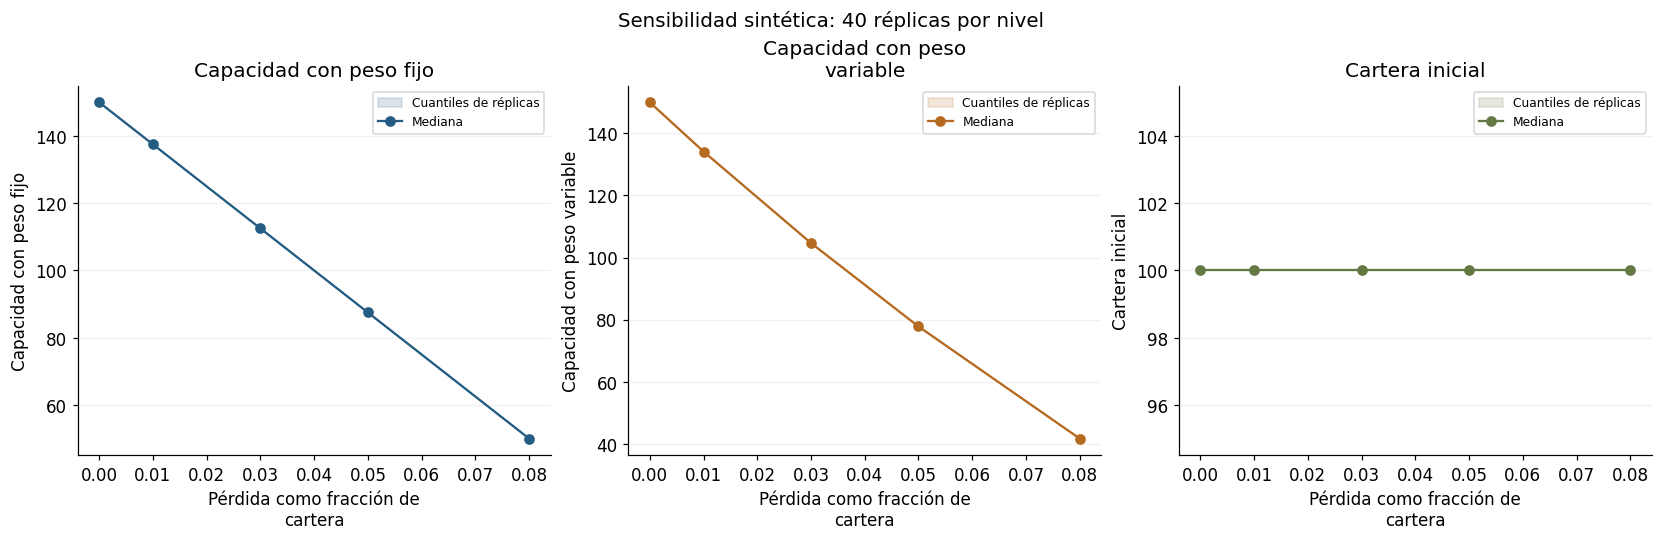

In [5]:
import textwrap
fig,axes=plt.subplots(1,len(METRICS),figsize=(15,4.8),layout='constrained')
for index,(ax,name) in enumerate(zip(np.atleast_1d(axes),METRICS)):
    group=summary[summary.metrica==name].sort_values('nivel')
    ax.fill_between(group.nivel,group.q025,group.q975,color=COLORS[index%3],alpha=.17,label='Cuantiles de réplicas')
    ax.plot(group.nivel,group.mediana,'o-',color=COLORS[index%3],label='Mediana')
    ax.set(title='\n'.join(textwrap.wrap(name,25)),xlabel='\n'.join(textwrap.wrap('Pérdida como fracción de cartera',30)),ylabel=name)
    ax.grid(axis='y',alpha=.18); ax.legend(fontsize=8)
fig.suptitle('Sensibilidad sintética: 40 réplicas por nivel',fontsize=13)
plt.show()


## Lectura de resultados ejecutados

El contraste siguiente se calcula con las salidas de la ejecución, sin fijar de antemano el signo de la conclusión. Debe interpretarse junto con los supuestos y la variación entre réplicas.

In [6]:
for name in METRICS:
    group=summary[summary.metrica==name].sort_values('nivel')
    first,last=group.iloc[0],group.iloc[-1]
    print(f"{name}: mediana {first['mediana']:.6g} en nivel {first['nivel']:g}; "
          f"{last['mediana']:.6g} en nivel {last['nivel']:g}.")
    print(f"  Último escenario: cuantiles [{last['q025']:.6g}, {last['q975']:.6g}], "
          f"media {last['media']:.6g}, error MC de la media {last['se_media_mc']:.3g}.")


Capacidad con peso fijo: mediana 150 en nivel 0; 50 en nivel 0.08.
  Último escenario: cuantiles [50, 50], media 50, error MC de la media 0.
Capacidad con peso variable: mediana 150 en nivel 0; 41.6667 en nivel 0.08.
  Último escenario: cuantiles [41.6667, 41.6667], media 41.6667, error MC de la media 0.
Cartera inicial: mediana 100 en nivel 0; 100 en nivel 0.08.
  Último escenario: cuantiles [100, 100], media 100, error MC de la media 0.


## Comprobaciones y controles

La reproducibilidad exige que la misma semilla reconstruya las mismas métricas. Los asserts estructurales de la función no dependen de que un estimador estocástico gane a otro en esta realización. Los conteos se reconcilian para no perder réplicas silenciosamente.

In [7]:
repeated,_=experiment(np.random.default_rng(SEED),central)
assert all(np.isclose(example[k],repeated[k],rtol=0,atol=1e-12) for k in METRICS)
assert len(raw)==len(GRID)*REPLICATIONS*len(METRICS)
assert summary.n.eq(REPLICATIONS).all()
assert (summary.q025<=summary.mediana+1e-12).all()
assert (summary.mediana<=summary.q975+1e-12).all()
print('Semilla, finitud, cuantiles y totalidad de réplicas: correctos.')


Semilla, finitud, cuantiles y totalidad de réplicas: correctos.


## Límites y siguiente contraste

No calcula solvencia normativa de Colombia. La respuesta real depende de absorción de pérdidas, provisiones, utilidades y capacidad de captar capital.

Antes de incorporar datos observados se debe fijar unidad de análisis, fecha de disponibilidad, reglas de exclusión y población de evaluación. La ampliación demuestra un mecanismo acotado; no convierte el proyecto en modelo validado externamente.

## Trazabilidad

Desarrollo semanal sobre `865c326`, revisión del 18-10-2026 UTC (noche del 17-10 en Colombia). El historial Git conserva el baseline genérico anterior. Todos los datos nuevos se regeneran desde la función `experiment`; las salidas del notebook se guardan después de ejecutar sus celdas de principio a fin.